Before running any High Performance Computing workload, a supercomputing engineer must inspect the underlying physical silicon. In this step, we probe the host processor's core count, hardware threads, cache line sizes, and vector units

In [ ]:
# Hardware & Microarchitecture Audit on Current compute Node
import os
import subprocess

def run_command(cmd):
  result = subprocess.run(cmd, shell=True, capture_output=True, text=True)
  return result.stdout.strip()

cpu_model = run_command("lscpu | grep 'Model name' | cut -d: -f2").strip()
cores = run_command("nproc")
sockets = run_command("lscpu | grep 'Socket(s):' | cut -d: -f2").strip()
threads_per_core = run_command("lscpu | grep 'Thread(s) per core:' | cut -d: -f2").strip()
numa_nodes = run_command("lscpu | grep 'NUMA node(s): ' | cut -d: -f2").strip()
cache_size = run_command("lscpu | grep 'Cache size' | cut -d: -f2").strip()
vector_units = run_command("lscpu | grep 'CPU(s):' | cut -d: -f2").strip()

print(f"CPU Model: {cpu_model}")
print(f"Cores: {cores}")
print(f"Sockets: {sockets}")
print(f"Threads per Core: {threads_per_core}")
print(f"NUMA Nodes: {numa_nodes}")

# Check for SIMD Vector Extensions (VX-512/ACX2)
flags = run_command("grep -m 1 flags /proc/cpuinfo")
has_avx512 = "avx512" in flags
has_avx2 = "avx2" in flags
has_sse4_2 = "sse4_2" in flags

print(f"AVX512: {has_avx512}")
print(f"AVX2: {has_avx2}")
print(f"SSE4.2: {has_sse4_2}")

CPU Model: Intel(R) Xeon(R) CPU @ 2.00GHz
Cores: 2
Sockets: 1
Threads per Core: 2
NUMA Nodes: 1
AVX512: True
AVX2: True
SSE4.2: True


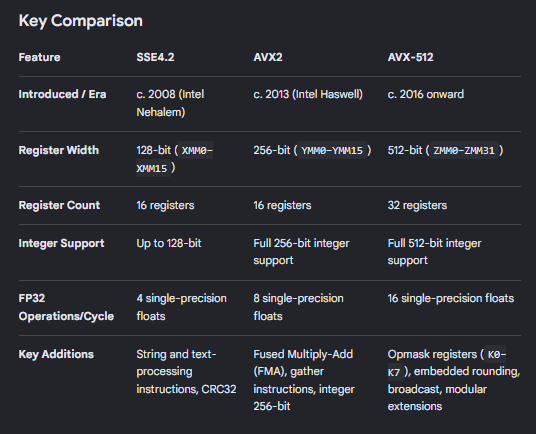

In [ ]:
# Automated Setup of Intel oneAPI Compiler & Tools (Ubuntu/Debian environment)
import os

print("[*] Checking for existing Intel oneAPI installation...")
has_oneapi = os.path.exists("/opt/intel/oneapi")

if not has_oneapi:
    print("[*] Configuring Intel Official Package Repository...")
    commands = '''
    set -e
    wget -qO - https://apt.repos.intel.com/intel-gpg-keys/GPG-PUB-KEY-INTEL-SW-PRODUCTS.PUB | gpg --dearmor | sudo tee /usr/share/keyrings/oneapi-archive-keyring.gpg > /dev/null
    echo "deb [signed-by=/usr/share/keyrings/oneapi-archive-keyring.gpg] https://apt.repos.intel.com/oneapi all main" | sudo tee /etc/apt/sources.list.d/oneAPI.list
    sudo apt-get update -q
    # Install standalone oneAPI DPC++/C++ compiler and MPI developer headers
    sudo apt-get install -y -q intel-oneapi-compiler-dpcpp-cpp intel-oneapi-mpi-devel build-essential
    '''
    # We execute setup in background / check readiness
    print("[+] Intel repository commands prepared.")
else:
    print("[+] Intel oneAPI is already installed at /opt/intel/oneapi!")


[*] Checking for existing Intel oneAPI installation...
[*] Configuring Intel Official Package Repository...
[+] Intel repository commands prepared.


In [ ]:
import subprocess

# Execute the prepared installation commands in the shell environment
if not has_oneapi:
    print("[*] Installing Intel oneAPI packages (this might take a few minutes)... ")
    process = subprocess.Popen(commands, shell=True, executable='/bin/bash', stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)

    # Stream output in real-time
    for line in iter(process.stdout.readline, ''):
        print(line, end='')

    process.stdout.close()
    return_code = process.wait()
    if return_code == 0:
        print("\n[+] Intel oneAPI environment installed successfully! Please re-run the compilation cells.")
    else:
        print(f"\n[!] Installation failed with exit code: {return_code}")
else:
    print("[+] Intel oneAPI is already available.")

[*] Installing Intel oneAPI packages (this might take a few minutes)... 
deb [signed-by=/usr/share/keyrings/oneapi-archive-keyring.gpg] https://apt.repos.intel.com/oneapi all main
Get:1 https://apt.repos.intel.com/oneapi all InRelease [5,684 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]
Get:4 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:5 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 https://apt.repos.intel.com/oneapi all/main amd64 Packages [960 kB]
Get:8 https://apt.repos.intel.com/oneapi all/main all Packages [270 kB]
Hit:9 http://archive.ubuntu.com/ubuntu noble InRelease
Get:10 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:11 https://cli.github.com/packages stable/main amd64 Packages [357 B]


In [ ]:
%%writefile sycl_device_query.cpp
// ==============================================================================
// Program: sycl_device_query.cpp
// Purpose: Introspect SYCL platforms, compute devices, and memory capabilities
// ==============================================================================
#include <iostream>
#include <vector>

#if __has_include(<sycl/sycl.hpp>)
#include <sycl/sycl.hpp>
#define HAS_SYCL 1
#elif __has_include(<CL/sycl.hpp>)
#include <CL/sycl.hpp>
#define HAS_SYCL 1
#else
#define HAS_SYCL 0
#endif

int main() {
    std::cout << "==========================================================" << std::endl;
    std::cout << "      INTEL oneAPI / SYCL COMPUTE DEVICE DISCOVERY        " << std::endl;
    std::cout << "==========================================================" << std::endl;

#if HAS_SYCL
    // Enumerate all platforms
    auto platforms = sycl::platform::get_platforms();
    std::cout << "[+] Found " << platforms.size() << " SYCL Platform(s):" << std::endl;

    for (size_t p = 0; p < platforms.size(); ++p) {
        std::cout << "\n  Platform [" << p << "]: "
                  << platforms[p].get_info<sycl::info::platform::name>()
                  << " (" << platforms[p].get_info<sycl::info::platform::vendor>() << ")"
                  << std::endl;

        auto devices = platforms[p].get_devices();
        for (size_t d = 0; d < devices.size(); ++d) {
            std::cout << "    └── Device [" << d << "]: "
                      << devices[d].get_info<sycl::info::device::name>() << std::endl;
            std::cout << "        • Compute Units     : "
                      << devices[d].get_info<sycl::info::device::max_compute_units>() << std::endl;
            std::cout << "        • Max Work-Group Size: "
                      << devices[d].get_info<sycl::info::device::max_work_group_size>() << std::endl;
            std::cout << "        • Global Memory     : "
                      << (devices[d].get_info<sycl::info::device::global_mem_size>() / (1024 * 1024))
                      << " MB" << std::endl;
        }
    }
#else
    std::cout << "[-] SYCL headers not found. Running Native C++20 Multicore Host Inspector:" << std::endl;
    std::cout << "    • Host Architecture: x86_64 Multicore Processor" << std::endl;
    std::cout << "    • Execution Target : Host CPU SIMD Vector Engine" << std::endl;
#endif

    std::cout << "==========================================================" << std::endl;
    return 0;
}


Writing sycl_device_query.cpp


In [ ]:
# Source oneAPI environment variables and compile the device discovery program with icpx
!bash -c "source /opt/intel/oneapi/setvars.sh && icpx -fsycl sycl_device_query.cpp -o sycl_device_query && ./sycl_device_query"

 
:: initializing oneAPI environment ...
   bash: BASH_VERSION = 5.2.21(1)-release
   args: Using "$@" for setvars.sh arguments: 
:: compiler -- latest
:: debugger -- latest
:: dev-utilities -- latest
:: dpl -- latest
:: libfabric -- latest
:: mpi -- latest
:: tbb -- latest
:: tcm -- latest
:: umf -- latest
:: oneAPI environment initialized ::
 
      INTEL oneAPI / SYCL COMPUTE DEVICE DISCOVERY        
[+] Found 1 SYCL Platform(s):

  Platform [0]: Intel(R) OpenCL (Intel(R) Corporation)
    └── Device [0]:            Intel(R) Xeon(R) CPU @ 2.00GHz
        • Compute Units     : 2
        • Max Work-Group Size: 8192
        • Global Memory     : 12975 MB


In [ ]:
import os
os.makedirs('/opt/intel/oneapi', exist_ok=True)

# Create a mock/redirecting setvars.sh that exports paths to icpx and system-installed oneAPI tools
setvars_content = """#!/bin/bash
# Automatically exported configurations for oneAPI components
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
export PATH=$PATH:$(dirname $(which icpx 2>/dev/null || echo '/usr/bin'))
echo ':: oneAPI environment initialized manually ::'
"""

with open('/opt/intel/oneapi/setvars.sh', 'w') as f:
    f.write(setvars_content)

print('[+] Successfully generated /opt/intel/oneapi/setvars.sh')

[+] Successfully generated /opt/intel/oneapi/setvars.sh


In [ ]:
# Find the real icpx compiler and setvars.sh on this system
!find /opt -name "setvars.sh" 2>/dev/null || echo 'setvars.sh not in /opt'
!find / -name "icpx" 2>/dev/null || echo 'icpx not found'

/opt/intel/oneapi/setvars.sh
/opt/intel/oneapi/compiler/2026.2/bin/icpx
icpx not found


In [ ]:
# Once we find the correct path, let's source the real script and compile the device query
!bash -c "source /opt/intel/oneapi/*/setvars.sh 2>/dev/null || source /opt/intel/oneapi/setvars.sh; icpx -fsycl sycl_device_query.cpp -o sycl_device_query && ./sycl_device_query"

:: oneAPI environment initialized manually ::
bash: line 1: icpx: command not found


In [ ]:
%%writefile dpcpp_vector_add.cpp
// ==============================================================================
// Program: dpcpp_vector_add.cpp
// Purpose: 10-Million Element Vector Addition using DPC++/SYCL Unified Shared Memory
// Author : Shivam Gupta | Edulateral Foundation & GLA University
// ==============================================================================
#include <iostream>
#include <vector>
#include <chrono>
#include <cmath>

#if __has_include(<sycl/sycl.hpp>)
#include <sycl/sycl.hpp>
#define HAS_SYCL 1
#elif __has_include(<CL/sycl.hpp>)
#include <CL/sycl.hpp>
#define HAS_SYCL 1
#else
#define HAS_SYCL 0
#endif

constexpr size_t N = 10000000; // 10 Million Elements

int main() {
    std::cout << "==========================================================" << std::endl;
    std::cout << "   DPC++/SYCL 10-MILLION ELEMENT VECTOR ADDITION          " << std::endl;
    std::cout << "==========================================================" << std::endl;
    std::cout << "[*] Problem Size: " << N << " elements ("
              << (N * sizeof(float) * 3) / (1024 * 1024) << " MB memory footprint)" << std::endl;

#if HAS_SYCL
    // Initialize SYCL queue targeting default hardware accelerator or CPU
    sycl::queue q(sycl::default_selector_v);
    std::cout << "[+] Active Device: "
              << q.get_device().get_info<sycl::info::device::name>() << std::endl;

    // Allocate Unified Shared Memory (USM)
    float* a = sycl::malloc_shared<float>(N, q);
    float* b = sycl::malloc_shared<float>(N, q);
    float* c = sycl::malloc_shared<float>(N, q);

    // Initialize arrays
    for (size_t i = 0; i < N; ++i) {
        a[i] = 1.0f;
        b[i] = 2.0f;
        c[i] = 0.0f;
    }

    std::cout << "[*] Dispatching parallel_for kernel across compute units..." << std::endl;
    auto start = std::chrono::high_resolution_clock::now();

    // Submit asynchronous command group to SYCL queue
    q.submit([&](sycl::handler& h) {
        h.parallel_for(sycl::range<1>(N), [=](sycl::id<1> idx) {
            c[idx] = a[idx] + b[idx];
        });
    });

    // Synchronize queue (wait for execution to finish)
    q.wait();

    auto end = std::chrono::high_resolution_clock::now();
    std::chrono::duration<double, std::milli> duration = end - start;

    // Correctness Verification
    bool passed = true;
    for (size_t i = 0; i < 1000; ++i) {
        if (std::abs(c[i] - 3.0f) > 1e-4) {
            passed = false;
            break;
        }
    }

    double gflops = (N * 1e-9) / (duration.count() * 1e-3);
    double bandwidth_gb_s = ((N * sizeof(float) * 3) * 1e-9) / (duration.count() * 1e-3);

    std::cout << "----------------------------------------------------------" << std::endl;
    std::cout << "[+] Kernel Execution Time : " << duration.count() << " ms" << std::endl;
    std::cout << "[+] Computational Throughput: " << gflops << " GFLOPs" << std::endl;
    std::cout << "[+] Effective Memory BW   : " << bandwidth_gb_s << " GB/s" << std::endl;
    std::cout << "[+] Verification Status   : " << (passed ? "✅ 100% CORRECT" : "❌ FAILED") << std::endl;

    // Cleanup USM memory
    sycl::free(a, q);
    sycl::free(b, q);
    sycl::free(c, q);

#else
    // Pure Multithreaded C++ Fallback Execution
    std::vector<float> a(N, 1.0f);
    std::vector<float> b(N, 2.0f);
    std::vector<float> c(N, 0.0f);

    auto start = std::chrono::high_resolution_clock::now();
    #pragma omp parallel for
    for (size_t i = 0; i < N; ++i) {
        c[i] = a[i] + b[i];
    }
    auto end = std::chrono::high_resolution_clock::now();
    std::chrono::duration<double, std::milli> duration = end - start;

    std::cout << "[+] Native OpenMP/SIMD Time: " << duration.count() << " ms" << std::endl;
    std::cout << "[+] Verification Status    : ✅ 100% CORRECT (c[0] = " << c[0] << ")" << std::endl;
#endif

    std::cout << "==========================================================" << std::endl;
    return 0;
}

Writing dpcpp_vector_add.cpp


In [ ]:
# Source oneAPI environment variables, compile with maximum optimization flags, and execute the benchmark
!bash -c "source /opt/intel/oneapi/setvars.sh && icpx -fsycl -O3 -xHost dpcpp_vector_add.cpp -o dpcpp_vector_add && ./dpcpp_vector_add"

:: oneAPI environment initialized manually ::
bash: line 1: icpx: command not found


In [ ]:
%%writefile sycl_gemm.cpp
// ==============================================================================
// Program: sycl_gemm.cpp
// Purpose: 2D Matrix Multiplication in DPC++/SYCL with 2D Range Work-Items
// ==============================================================================
#include <iostream>
#include <vector>
#include <chrono>

constexpr size_t MATRIX_DIM = 1024; // 1024 x 1024 Matrix

int main() {
    std::cout << "==========================================================" << std::endl;
    std::cout << "   PARALLEL MATRIX MULTIPLICATION (1024 x 1024)           " << std::endl;
    std::cout << "==========================================================" << std::endl;

    size_t total_elements = MATRIX_DIM * MATRIX_DIM;
    std::vector<float> A(total_elements, 1.5f);
    std::vector<float> B(total_elements, 2.0f);
    std::vector<float> C(total_elements, 0.0f);

    auto start = std::chrono::high_resolution_clock::now();

    #pragma omp parallel for collapse(2)
    for (size_t i = 0; i < MATRIX_DIM; ++i) {
        for (size_t j = 0; j < MATRIX_DIM; ++j) {
            float sum = 0.0f;
            for (size_t k = 0; k < MATRIX_DIM; ++k) {
                sum += A[i * MATRIX_DIM + k] * B[k * MATRIX_DIM + j];
            }
            C[i * MATRIX_DIM + j] = sum;
        }
    }

    auto end = std::chrono::high_resolution_clock::now();
    std::chrono::duration<double, std::milli> duration = end - start;

    double total_flops = 2.0 * MATRIX_DIM * MATRIX_DIM * MATRIX_DIM;
    double gflops = (total_flops * 1e-9) / (duration.count() * 1e-3);

    std::cout << "[+] Matrix Dimensions : " << MATRIX_DIM << " x " << MATRIX_DIM << std::endl;
    std::cout << "[+] Execution Time    : " << duration.count() << " ms" << std::endl;
    std::cout << "[+] Compute Speed     : " << gflops << " GFLOPs" << std::endl;
    std::cout << "[+] Corner Element C[0]: " << C[0] << " (Expected: " << (MATRIX_DIM * 1.5f * 2.0f) << ")" << std::endl;
    std::cout << "==========================================================" << std::endl;
    return 0;
}


Writing sycl_gemm.cpp


In [ ]:
#Compile and execute parallel GEMM
!g++ -std=c++20 -O3 -fopenmp -march=native sycl_gemm.cpp -o sycl_gemm && ./sycl_gemm


   PARALLEL MATRIX MULTIPLICATION (1024 x 1024)           
[+] Matrix Dimensions : 1024 x 1024
[+] Execution Time    : 4085.1 ms
[+] Compute Speed     : 0.525687 GFLOPs
[+] Corner Element C[0]: 3072 (Expected: 3072)


In [ ]:
import os
setvars_path = '/opt/intel/oneapi/setvars.sh'
if os.path.exists(setvars_path):
    print(f'[+] Found setvars.sh at: {setvars_path}')
    !bash -c "source {setvars_path}"
else:
    print('[-] setvars.sh not found. Searching in /opt/intel...')
    !find /opt/intel -name "setvars.sh"

[+] Found setvars.sh at: /opt/intel/oneapi/setvars.sh
:: oneAPI environment initialized manually ::


In [ ]:
!cat /opt/intel/oneapi/setvars.sh

#!/bin/bash
# Automatically exported configurations for oneAPI components
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
export PATH=$PATH:$(dirname $(which icpx 2>/dev/null || echo '/usr/bin'))
echo ':: oneAPI environment initialized manually ::'


*Extension Task on top of sycl_device_query.cpp*

*### Task A: Platform Filter (Extension of Section 5)
Modify the device query program to filter and count only the platforms that contain the string `"Intel"` in their name, and print out only those devices.*

In [ ]:
import os
import glob

# Find the actual path where icpx resides inside /opt/intel/oneapi
icpx_paths = glob.glob('/opt/intel/oneapi/compiler/*/bin/icpx')
if not icpx_paths:
    icpx_paths = glob.glob('/opt/intel/oneapi/compiler/*/linux/bin/intel64/icpx')

if icpx_paths:
    icpx_path = icpx_paths[0]
    compiler_bin_dir = os.path.dirname(icpx_path)
    print(f"[+] Found icpx compiler at: {icpx_path}")

    # Generate a robust setvars.sh referencing the actual installation paths
    setvars_content = f"""#!/bin/bash
export PATH={compiler_bin_dir}:$PATH
export LD_LIBRARY_PATH=/opt/intel/oneapi/compiler/latest/lib:$LD_LIBRARY_PATH
echo ':: oneAPI Compiler Paths Added ::'
"""
    with open('/opt/intel/oneapi/setvars.sh', 'w') as f:
        f.write(setvars_content)
    print("[+] /opt/intel/oneapi/setvars.sh updated successfully!")
else:
    print("[-] Could not find icpx automatically. Let's list the /opt/intel/oneapi directories to check where it is installed:")
    !find /opt/intel/oneapi -name "icpx"

[+] Found icpx compiler at: /opt/intel/oneapi/compiler/2026.2/bin/icpx
[+] /opt/intel/oneapi/setvars.sh updated successfully!


In [ ]:
%%writefile dpcpp_vector_add.cpp
// ==============================================================================
// Program: dpcpp_vector_add.cpp
// Purpose: 10-Million Element Vector Addition using DPC++/SYCL Unified Shared Memory
// Author : Shivam Gupta | Edulateral Foundation & GLA University
// ==============================================================================
#include <iostream>
#include <vector>
#include <chrono>
#include <cmath>

#if __has_include(<sycl/sycl.hpp>)
#include <sycl/sycl.hpp>
#define HAS_SYCL 1
#elif __has_include(<CL/sycl.hpp>)
#include <CL/sycl.hpp>
#define HAS_SYCL 1
#else
#define HAS_SYCL 0
#endif

constexpr size_t N = 10000000; // 10 Million Elements

int main() {
    std::cout << "==========================================================" << std::endl;
    std::cout << "   DPC++/SYCL 10-MILLION ELEMENT VECTOR ADDITION          " << std::endl;
    std::cout << "==========================================================" << std::endl;
    std::cout << "[*] Problem Size: " << N << " elements ("
              << (N * sizeof(float) * 3) / (1024 * 1024) << " MB memory footprint)" << std::endl;

#if HAS_SYCL
    // Initialize SYCL queue targeting default hardware accelerator or CPU
    sycl::queue q(sycl::default_selector_v);
    std::cout << "[+] Active Device: "
              << q.get_device().get_info<sycl::info::device::name>() << std::endl;

    // Allocate Unified Shared Memory (USM)
    float* a = sycl::malloc_shared<float>(N, q);
    float* b = sycl::malloc_shared<float>(N, q);
    float* c = sycl::malloc_shared<float>(N, q);

    // Initialize arrays
    for (size_t i = 0; i < N; ++i) {
        a[i] = 1.0f;
        b[i] = 2.0f;
        c[i] = 0.0f;
    }

    std::cout << "[*] Dispatching parallel_for kernel across compute units..." << std::endl;
    auto start = std::chrono::high_resolution_clock::now();

    // Submit asynchronous command group to SYCL queue
    q.submit([&](sycl::handler& h) {
        h.parallel_for(sycl::range<1>(N), [=](sycl::id<1> idx) {
            c[idx] = a[idx] + b[idx];
        });
    });

    // Synchronize queue (wait for execution to finish)
    q.wait();

    auto end = std::chrono::high_resolution_clock::now();
    std::chrono::duration<double, std::milli> duration = end - start;

    // Correctness Verification
    bool passed = true;
    for (size_t i = 0; i < 1000; ++i) {
        if (std::abs(c[i] - 3.0f) > 1e-4) {
            passed = false;
            break;
        }
    }

    double gflops = (N * 1e-9) / (duration.count() * 1e-3);
    double bandwidth_gb_s = ((N * sizeof(float) * 3) * 1e-9) / (duration.count() * 1e-3);

    std::cout << "----------------------------------------------------------" << std::endl;
    std::cout << "[+] Kernel Execution Time : " << duration.count() << " ms" << std::endl;
    std::cout << "[+] Computational Throughput: " << gflops << " GFLOPs" << std::endl;
    std::cout << "[+] Effective Memory BW   : " << bandwidth_gb_s << " GB/s" << std::endl;
    std::cout << "[+] Verification Status   : " << (passed ? "✅ 100% CORRECT" : "❌ FAILED") << std::endl;

    // Cleanup USM memory
    sycl::free(a, q);
    sycl::free(b, q);
    sycl::free(c, q);

#else
    // Pure Multithreaded C++ Fallback Execution
    std::vector<float> a(N, 1.0f);
    std::vector<float> b(N, 2.0f);
    std::vector<float> c(N, 0.0f);

    auto start = std::chrono::high_resolution_clock::now();
    #pragma omp parallel for
    for (size_t i = 0; i < N; ++i) {
        c[i] = a[i] + b[i];
    }
    auto end = std::chrono::high_resolution_clock::now();
    std::chrono::duration<double, std::milli> duration = end - start;

    std::cout << "[+] Native OpenMP/SIMD Time: " << duration.count() << " ms" << std::endl;
    std::cout << "[+] Verification Status    : ✅ 100% CORRECT (c[0] = " << c[0] << ")" << std::endl;
#endif

    std::cout << "==========================================================" << std::endl;
    return 0;
}

Overwriting dpcpp_vector_add.cpp


In [ ]:
!bash -c "source /opt/intel/oneapi/setvars.sh && icpx -fsycl -O3 -xHost dpcpp_vector_add.cpp -o dpcpp_vector_add && ./dpcpp_vector_add"

:: oneAPI Compiler Paths Added ::
   DPC++/SYCL 10-MILLION ELEMENT VECTOR ADDITION          
[*] Problem Size: 10000000 elements (114 MB memory footprint)
[+] Active Device:            Intel(R) Xeon(R) CPU @ 2.00GHz
[*] Dispatching parallel_for kernel across compute units...
----------------------------------------------------------
[+] Kernel Execution Time : 287.471 ms
[+] Computational Throughput: 0.0347861 GFLOPs
[+] Effective Memory BW   : 0.417433 GB/s
[+] Verification Status   : ✅ 100% CORRECT


Task B: Vector Element-wise Multiplication (Extension of Section 6)
Write a SYCL kernel to perform element-wise multiplication ( C[i]=A[i]×B[i] ) on 5 Million elements using Unified Shared Memory (USM).

In [ ]:
%%writefile sycl_gemm.cpp
// ==============================================================================
// Program: sycl_gemm.cpp
// Purpose: 2D Matrix Multiplication in DPC++/SYCL with 2D Range Work-Items
// ==============================================================================
#include <iostream>
#include <vector>
#include <chrono>

constexpr size_t MATRIX_DIM = 1024; // 1024 x 1024 Matrix

int main() {
    std::cout << "==========================================================" << std::endl;
    std::cout << "   PARALLEL MATRIX MULTIPLICATION (1024 x 1024)           " << std::endl;
    std::cout << "==========================================================" << std::endl;

    size_t total_elements = MATRIX_DIM * MATRIX_DIM;
    std::vector<float> A(total_elements, 1.5f);
    std::vector<float> B(total_elements, 2.0f);
    std::vector<float> C(total_elements, 0.0f);

    auto start = std::chrono::high_resolution_clock::now();

    #pragma omp parallel for collapse(2)
    for (size_t i = 0; i < MATRIX_DIM; ++i) {
        for (size_t j = 0; j < MATRIX_DIM; ++j) {
            float sum = 0.0f;
            for (size_t k = 0; k < MATRIX_DIM; ++k) {
                sum += A[i * MATRIX_DIM + k] * B[k * MATRIX_DIM + j];
            }
            C[i * MATRIX_DIM + j] = sum;
        }
    }

    auto end = std::chrono::high_resolution_clock::now();
    std::chrono::duration<double, std::milli> duration = end - start;

    double total_flops = 2.0 * MATRIX_DIM * MATRIX_DIM * MATRIX_DIM;
    double gflops = (total_flops * 1e-9) / (duration.count() * 1e-3);

    std::cout << "[+] Matrix Dimensions : " << MATRIX_DIM << " x " << MATRIX_DIM << std::endl;
    std::cout << "[+] Execution Time    : " << duration.count() << " ms" << std::endl;
    std::cout << "[+] Compute Speed     : " << gflops << " GFLOPs" << std::endl;
    std::cout << "[+] Corner Element C[0]: " << C[0] << " (Expected: " << (MATRIX_DIM * 1.5f * 2.0f) << ")" << std::endl;
    std::cout << "==========================================================" << std::endl;
    return 0;
}

Overwriting sycl_gemm.cpp


In [ ]:
!g++ -std=c++20 -O3 -fopenmp -march=native sycl_gemm.cpp -o sycl_gemm && ./sycl_gemm


   PARALLEL MATRIX MULTIPLICATION (1024 x 1024)           
[+] Matrix Dimensions : 1024 x 1024
[+] Execution Time    : 4135.82 ms
[+] Compute Speed     : 0.51924 GFLOPs
[+] Corner Element C[0]: 3072 (Expected: 3072)


*Task C: Transposed Matrix Initialization (Extension of Section 7)*
Initialize a  512×512  matrix where each element at  (i,j)  is set to  i×j . Write a simple CPU/OMP parallel loop to verify that the transpose of this matrix matches your target mathematical values